1. Dataset Requirements & Deadlines
Source: Choose dataset from Kaggle.

Size: It should have at least 2,000 rows. (Under special circumstances, I may approve datasets less than 2,000 rows, but the absolute minimum is 1,000 rows).

Timeline: Start looking for a dataset TODAY (it takes 2 weeks to finalize the dataset and get my approval).

Deadline: Present your dataset for approval by me before October 12, 2026.

⚠️ Warning: If your dataset is not approved by me, your project submission will NOT be graded.

2. Pre-Processing & Cleanup Requirements
Once approved, perform a cleanup on the dataset using the guidelines you learned in Modules 4 and 5.

Some of the pre-processing exercises to be performed on the dataset are:

Filling NaN and Null values with appropriate values

Scaling: Changing the range of your data

Normalization: Adjusting the shape of your data's distribution

Class Balancing the dataset

One-hot encoding

Encoding: Converting categorical data to numbers

Feature engineering

🚨 CRITICAL RULE: NEVER EVER change the dataset manually. If you do this, you have failed the exam. All changes must be done via Python code in Jupyter Lab.

3. Notebook & Visualization Requirements
Matplotlib: Use Matplotlib to plot the data distributions in the code and show how the data before and after preprocessing looks like (e.g., balancing the dataset).

Sample Data: Print sample data as it gets processed in the code.

Jupyter Notebook: Build a Jupyter notebook to show the dataset before and after cleanup.

ML Problem Discussion: Discuss how you would use this dataset to solve an ML problem.

In [1]:
# pip install matplotlib numpy pandas seaborn scikit-learn
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder


In [2]:
DATA_URL = "/content/sample_data/dataset.csv"
df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print("\nFirst five rows:")
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/sample_data/dataset.csv'

In [ ]:
print("\nData types and non-null counts:")
df.info()

print("\nDescriptive statistics:")
print(df.describe(include="all").transpose())

print("\nMissing values by column:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nUnique values in categorical columns:")
for column in ["Test Results", "Medication", "Medical Condition", "Blood Type", "Gender", "Age", "Admission Type"]:
    print(f"{column}: {df[column].dropna().unique().tolist()}")

# A target distribution check tells us whether the classes are balanced.
# If one class is much larger, accuracy alone can be misleading.
print("\nTest Result Counts:")
print(df["Test Results"].value_counts().rename(index={0: "Normal", 1: "Inconclusive", 2: "Abnormal"}))


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64

/tmp/ipykernel_1029/228441638.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(["Abnormal", "Normal", "Inconclusive"])


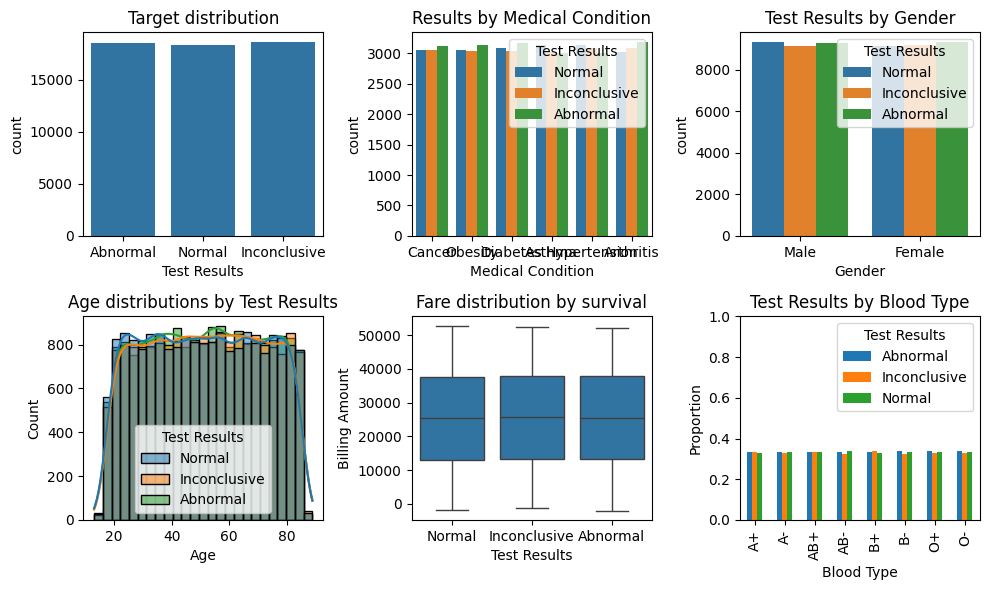


Test Results by Gender:
Test Results  Abnormal  Inconclusive    Normal
Gender                                        
Female        0.336796      0.332396  0.330809
Male          0.334449      0.329085  0.336466

Test Results by Medical Condition:
Test Results       Abnormal  Inconclusive    Normal
Medical Condition                                  
Arthritis          0.342501      0.331758  0.325741
Asthma             0.327599      0.329777  0.342624
Cancer             0.337921      0.331635  0.330443
Diabetes           0.340499      0.327386  0.332115
Hypertension       0.325798      0.334343  0.339859
Obesity            0.339292      0.329542  0.331167


In [ ]:
ig, axes = plt.subplots(2, 3, figsize=(16, 10))

sns.countplot(data=df, x="Test Results", ax=axes[0, 0])
axes[0, 0].set_title("Target distribution")
axes[0, 0].set_xticklabels(["Abnormal", "Normal", "Inconclusive"])

sns.countplot(data=df, x="Medical Condition", hue="Test Results", ax=axes[0, 1])
axes[0, 1].set_title("Results by Medical Condition")

sns.countplot(data=df, x="Gender", hue="Test Results", ax=axes[0, 2])
axes[0, 2].set_title("Test Results by Gender")

sns.histplot(data=df, x="Age", hue="Test Results", bins=25, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Age distributions by Test Results")

sns.boxplot(data=df, x="Test Results", y="Billing Amount", ax=axes[1, 1])
axes[1, 1].set_title("Fare distribution by survival")

result_by_blood_type = pd.crosstab(
    df["Blood Type"],
    df["Test Results"],
    normalize="index"
)

result_by_blood_type.plot(
    kind="bar",
    ax=axes[1, 2],
    figsize=(10, 6)
)

axes[1, 2].set_title("Test Results by Blood Type")
axes[1, 2].set_xlabel("Blood Type")
axes[1, 2].set_ylabel("Proportion")
axes[1, 2].set_ylim(0, 1)
axes[1, 2].legend(title="Test Results")

plt.tight_layout()
plt.show()

print("\nTest Results by Gender:")
test_results_by_gender = pd.crosstab(
    df["Gender"],
    df["Test Results"],
    normalize="index"
)

print(test_results_by_gender)

print("\nTest Results by Medical Condition:")
test_results_by_condition = pd.crosstab(
    df["Medical Condition"],
    df["Test Results"],
    normalize="index"
)

print(test_results_by_condition)

In [ ]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(df["Test Results"])
print("Original labels:")
print(label_encoder.classes_)

for number, label in enumerate(label_encoder.classes_):
    print(f"{label} = {number}")

print("\nNumeric labels:")
print(y[:10])

df["Test Results Encoded"] = y
print(df.head())


columns_to_drop = [
    "Test Results", # Feature to prodict
    "Name",
    "Date of Admission",
    "Doctor",
    "Hospital",
    "Insurance Provider",
    "Room Number",
    "Discharge Date"
]
X = df.drop(columns=columns_to_drop)


df_encoded = pd.get_dummies(
    X,
    columns=[
        "Medication",
        "Medical Condition",
        "Blood Type",
        "Gender",
        "Admission Type"
    ],
    dtype=int
)

print("\nEncoded feature data:")
print(df_encoded.head())

print("\nRemaining columns:")
print(df_encoded.columns.tolist())

Original labels:
['Abnormal' 'Inconclusive' 'Normal']
Abnormal = 0
Inconclusive = 1
Normal = 2

Numeric labels:
[2 1 2 0 0 2 1 1 0 1]
            Name  Age  Gender Blood Type Medical Condition Date of Admission  \
0  Bobby JacksOn   30    Male         B-            Cancer        2024-01-31   
1   LesLie TErRy   62    Male         A+           Obesity        2019-08-20   
2    DaNnY sMitH   76  Female         A-           Obesity        2022-09-22   
3   andrEw waTtS   28  Female         O+          Diabetes        2020-11-18   
4  adrIENNE bEll   43  Female        AB+            Cancer        2022-09-19   

             Doctor                    Hospital Insurance Provider  \
0     Matthew Smith             Sons and Miller         Blue Cross   
1   Samantha Davies                     Kim Inc           Medicare   
2  Tiffany Mitchell                    Cook PLC              Aetna   
3       Kevin Wells  Hernandez Rogers and Vang,           Medicare   
4    Kathleen Hanna                